Original Dataset:
   Study_Hours  Attendance  Assignment_Score  Exam_Score
0            2          60                40          45
1            4          65                50          50
2            6          70                55          60
3            8          75                65          65
4           10          80                70          75
5            3          62                45          48
6            5          68                60          58
7            7          78                72          70
8            9          85                80          82
9           12          95                90          95

Statistical Summary:
       Study_Hours  Attendance  Assignment_Score  Exam_Score
count    10.000000   10.000000         10.000000   10.000000
mean      6.600000   73.800000         62.700000   64.800000
std       3.204164   10.992927         15.797679   15.991664
min       2.000000   60.000000         40.000000   45.000000
25%       4.250000   65.7500

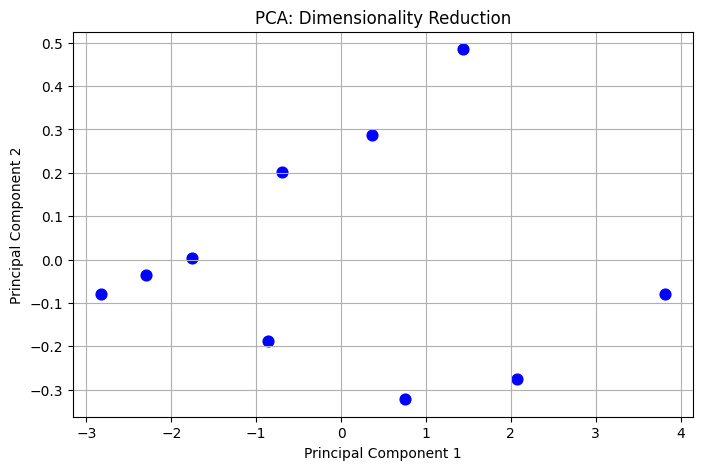

In [1]:

# Feature Engineering: Normalization, Standardization and PCA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# Step 1: Create a sample dataset
data = {
    'Study_Hours': [2, 4, 6, 8, 10, 3, 5, 7, 9, 12],
    'Attendance': [60, 65, 70, 75, 80, 62, 68, 78, 85, 95],
    'Assignment_Score': [40, 50, 55, 65, 70, 45, 60, 72, 80, 90],
    'Exam_Score': [45, 50, 60, 65, 75, 48, 58, 70, 82, 95]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

print("\nStatistical Summary:")
print(df.describe())

# Step 2: Normalization using MinMaxScaler
scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(df)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

print("\nNormalized Dataset:")
print(normalized_df.round(2))

print("\nMinimum Values:")
print(normalized_df.min().round(2))

print("\nMaximum Values:")
print(normalized_df.max().round(2))

# Step 3: Standardization using StandardScaler
scaler = StandardScaler()
standardized_data = scaler.fit_transform(df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("\nStandardized Dataset:")
print(standardized_df.round(2))

print("\nMean of Each Feature:")
print(standardized_df.mean().round(2))

print("\nStandard Deviation of Each Feature:")
print(standardized_df.std(ddof=0).round(2))

# Step 4: PCA for Dimensionality Reduction
# First standardize the dataset
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

# Reduce 4 features to 2 principal components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("\nPCA Transformed Data:")
print(pca_df.round(2))

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal Variance Retained:")
print(round(pca.explained_variance_ratio_.sum(), 4))

# Step 5: Visualize PCA output
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Dimensionality Reduction")
plt.grid(True)
plt.show()